# Pronóstico semanal del precio de bolsa (PAE)

Implementación de la propuesta del caso XM–UNAL. Pregunta: ¿en qué medida el embalse, los aportes, los precios de oferta térmicos y no térmicos, la utilización térmica y la fase ENOS permiten anticipar con una semana de antelación el precio de bolsa promedio semanal ponderado por demanda?

Datos: API de XM (mismo servicio que `pydataxm`, ver `README.md`) y ONI de NOAA, 2010 hasta la última semana completa.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

import xm_datos as xm
import variables as var
import modelo as mod

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (14, 6)
plt.rcParams["axes.titleweight"] = "bold"
pd.set_option("display.float_format", "{:,.3f}".format)

INICIO = "2010-01-01"
INICIO_PRUEBA = "2018-01-01"
INICIO_CALIBRACION = "2014-01-01"

## 1. Descarga y construcción de la tabla semanal

La primera ejecución descarga unos 200 meses por serie; las siguientes leen la caché de `datos/xm/`.

In [2]:
datos = xm.descargar_todo(INICIO)
listado = xm.listado_recursos()
sem, clases = var.construir(datos, listado)
sem.to_csv("datos/semanal.csv")
d = mod.preparar(sem)
print(f"Semanas: {len(sem)}  ({sem.index.min():%Y-%m-%d} a {sem.index.max():%Y-%m-%d})")
sem.tail()

precio             6,148 filas     1.4 s


demanda            6,148 filas     1.0 s


aportes            6,150 filas     1.1 s


aportes_media      6,150 filas     0.7 s


volumen_pct        6,150 filas     0.7 s


volumen_kwh        6,150 filas     1.4 s


... (2 outputs left out)

generacion     1,153,379 filas    10.3 s


combustible      109,605 filas     1.7 s


Semanas: 877  (2010-01-04 a 2026-10-19)


,precio,precio_max_h,demanda_gwh,precio_ultimo_dia,precio_std_diaria,aportes_gwh,aportes_pct_media,embalse_cierre,embalse_prom,embalse_cambio,...,oferta_no_termica,fut,participacion_termica,oni,oni_rezago,fase_enos,precio_sig,precio_ant,sen_semana,cos_semana
semana,,,,,,,,,,,,,,,,,,,,,
2026-09-21,681.736,"1,612.426","1,743.730",608.895,70.811,744.587,0.510,0.764,0.770,-0.017,...,306.668,0.552,0.336,1.800,0.460,1,737.751,576.232,-1.000,-0.016
2026-09-28,737.751,"2,001.671","1,707.310",655.652,63.054,"1,001.482",0.620,0.761,0.763,-0.003,...,333.191,0.548,0.344,1.800,0.460,1,695.725,681.736,-0.995,0.104
2026-10-05,695.725,"1,523.130","1,701.388",544.704,116.712,967.645,0.559,0.751,0.749,-0.011,...,357.364,0.548,0.348,1.800,0.460,1,595.900,737.751,-0.975,0.223
2026-10-12,595.900,"1,148.491","1,672.480",493.578,92.931,"1,156.614",0.668,0.763,0.759,0.012,...,334.727,0.586,0.380,2.160,0.950,1,569.832,695.725,-0.941,0.338
2026-10-19,569.832,"1,214.034","1,700.239",428.176,87.784,"1,050.300",0.607,0.767,0.764,0.004,...,307.020,0.612,0.390,2.160,0.950,1,NaN,595.900,-0.894,0.449


## 2. Calidad y cobertura

Semanas faltantes por variable y clasificación de los recursos térmicos. Los recursos que ya no aparecen en `ListadoRecursos` se clasifican por consumo de combustible.

In [3]:
cobertura = sem.notna().mean().rename("cobertura").to_frame()
cobertura["primera_semana"] = [sem[c].first_valid_index() for c in sem.columns]
display(cobertura)

gen_rec = datos["generacion"].groupby("codigo").valor.sum()
resumen_clases = clases.join(gen_rec.rename("gen_kwh")).groupby(["fuente", "termico"]).agg(
    recursos=("gen_kwh", "size"), gen_twh=("gen_kwh", lambda s: s.sum() / 1e9))
resumen_clases

,cobertura,primera_semana
precio,1.000,2010-01-04
precio_max_h,1.000,2010-01-04
demanda_gwh,1.000,2010-01-04
precio_ultimo_dia,1.000,2010-01-04
precio_std_diaria,1.000,2010-01-04
aportes_gwh,1.000,2010-01-04
aportes_pct_media,1.000,2010-01-04
embalse_cierre,1.000,2010-01-04
embalse_prom,1.000,2010-01-04
embalse_cambio,1.000,2010-01-04


recursos  gen_twh
fuente      termico                   
combustible False          54    2.908
            True           11    5.309
listado     False        2338  909.119
            True           93  265.452

## 3. Variabilidad del precio

Desviación del cambio semanal: 23.7 %
Semanas con |cambio| > 25 %: 24.1%


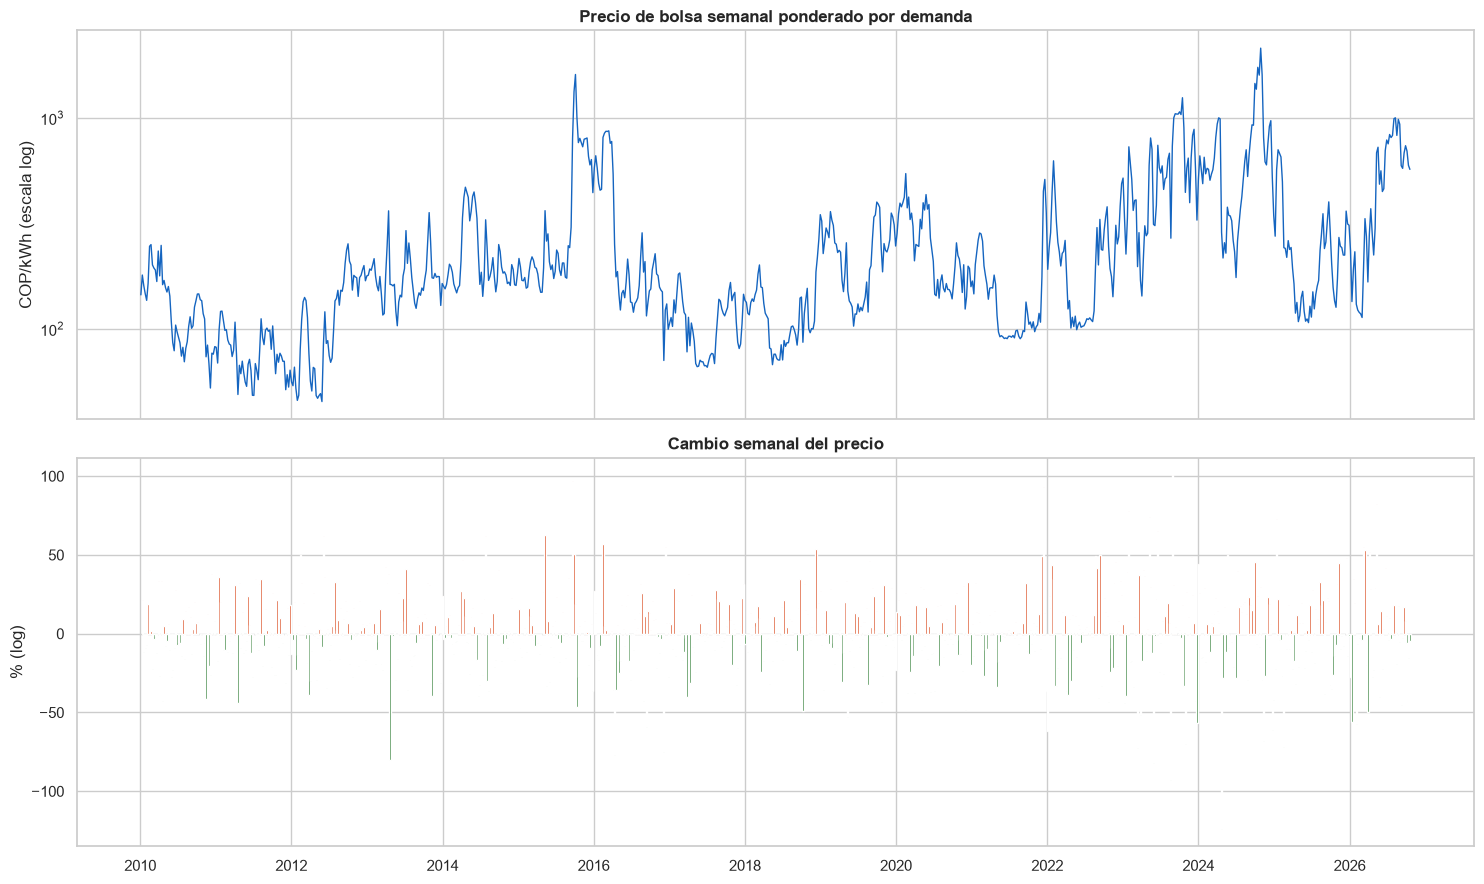

In [4]:
fig, axes = plt.subplots(2, 1, figsize=(15, 9), sharex=True)
axes[0].plot(sem.index, sem.precio, color="#1565c0", lw=1)
axes[0].set_yscale("log")
axes[0].set_title("Precio de bolsa semanal ponderado por demanda")
axes[0].set_ylabel("COP/kWh (escala log)")
cambio = np.log(sem.precio / sem.precio_ant) * 100
axes[1].bar(sem.index, cambio, width=6, color=np.where(cambio > 0, "#d84315", "#2e7d32"))
axes[1].set_title("Cambio semanal del precio")
axes[1].set_ylabel("% (log)")
plt.tight_layout()

print(f"Desviación del cambio semanal: {cambio.std():.1f} %")
print(f"Semanas con |cambio| > 25 %: {(cambio.abs() > 25).mean():.1%}")

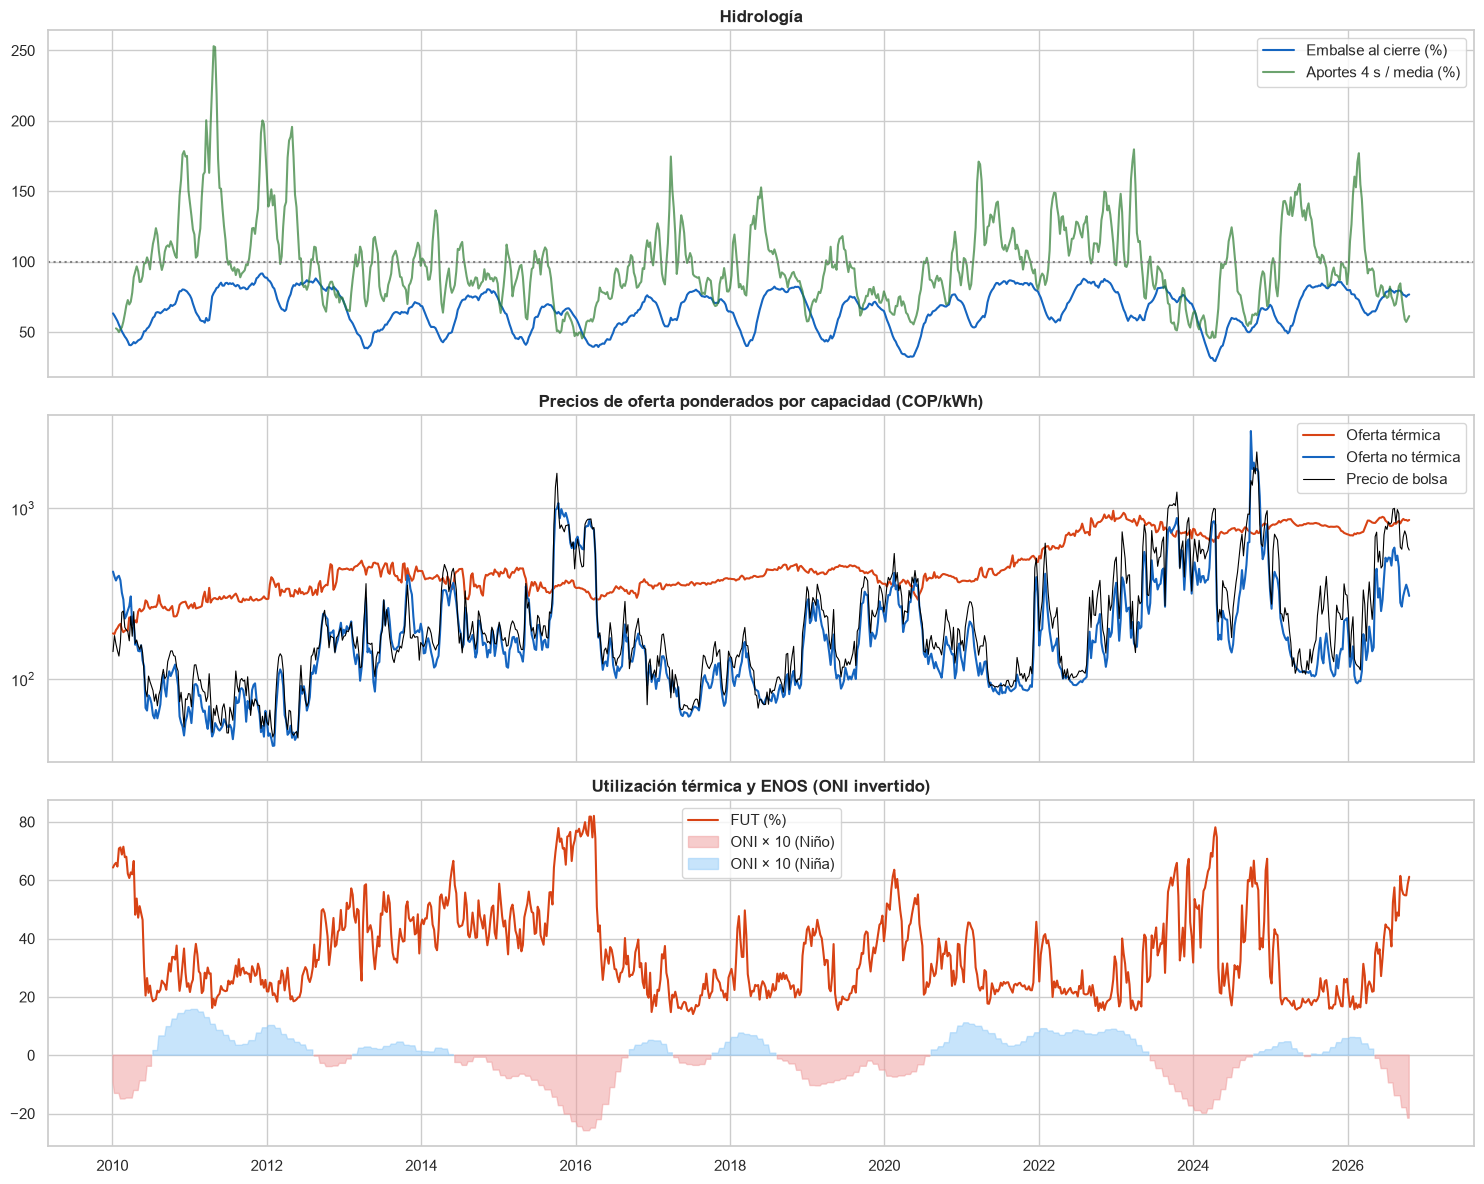

In [5]:
fig, axes = plt.subplots(3, 1, figsize=(15, 12), sharex=True)
axes[0].plot(sem.index, sem.embalse_cierre * 100, color="#1565c0", label="Embalse al cierre (%)")
axes[0].plot(sem.index, sem.aportes_pct_media_4s * 100, color="#2e7d32", alpha=0.7, label="Aportes 4 s / media (%)")
axes[0].axhline(100, color="gray", ls=":")
axes[0].legend(); axes[0].set_title("Hidrología")
axes[1].plot(sem.index, sem.oferta_termica, color="#d84315", label="Oferta térmica")
axes[1].plot(sem.index, sem.oferta_no_termica, color="#1565c0", label="Oferta no térmica")
axes[1].plot(sem.index, sem.precio, color="black", lw=0.8, label="Precio de bolsa")
axes[1].set_yscale("log"); axes[1].legend(); axes[1].set_title("Precios de oferta ponderados por capacidad (COP/kWh)")
axes[2].plot(sem.index, sem.fut * 100, color="#d84315", label="FUT (%)")
axes[2].fill_between(sem.index, -sem.oni * 10, 0, where=sem.oni > 0, color="#ef9a9a", alpha=0.5, label="ONI × 10 (Niño)")
axes[2].fill_between(sem.index, -sem.oni * 10, 0, where=sem.oni < 0, color="#90caf9", alpha=0.5, label="ONI × 10 (Niña)")
axes[2].legend(); axes[2].set_title("Utilización térmica y ENOS (ONI invertido)")
plt.tight_layout()

## 4. Asociaciones con el precio de la semana siguiente

Correlación de Spearman de cada variable de la semana s con el nivel log P_{s+1} y con el cambio log(P_{s+1}/P_s). Las asociaciones no se interpretan como causales.

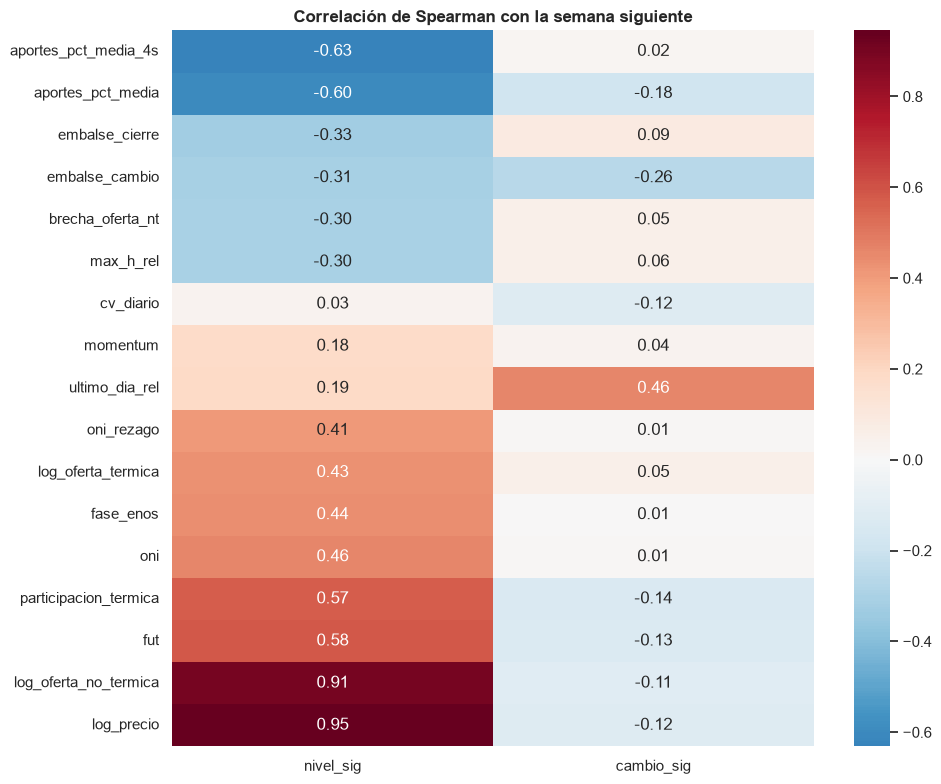

In [6]:
cols = [c for c in mod.VARIABLES if c not in ("sen_semana", "cos_semana")]
asoc = pd.DataFrame({
    "nivel_sig": d[cols].corrwith(np.log(d.precio_sig), method="spearman"),
    "cambio_sig": d[cols].corrwith(d.y, method="spearman"),
}).sort_values("nivel_sig")
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(asoc, annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=ax)
ax.set_title("Correlación de Spearman con la semana siguiente")
plt.tight_layout()

,0,4,8,12,16,20,24,28,32,36,40,44,48,52
spearman,0.460,0.450,0.440,0.420,0.400,0.360,0.320,0.270,0.220,0.170,0.120,0.060,0.020,-0.030


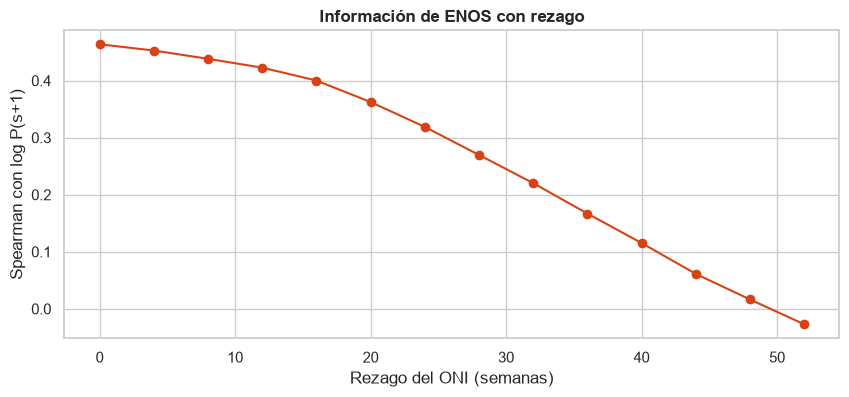

In [7]:
# ENOS con rezago: correlación del ONI publicado k semanas antes con el log del precio
rezagos = range(0, 53, 4)
corr_oni = pd.Series({k: d.oni.shift(k).corr(np.log(d.precio_sig), method="spearman") for k in rezagos})
ax = corr_oni.plot(marker="o", figsize=(10, 4), color="#d84315")
ax.set_xlabel("Rezago del ONI (semanas)"); ax.set_ylabel("Spearman con log P(s+1)")
ax.set_title("Información de ENOS con rezago")
corr_oni.round(2).to_frame("spearman").T

## 5. Evaluación fuera de muestra

Walk-forward con ventana expansiva: se reentrena cada 4 semanas con toda la historia anterior. Los pronósticos arrancan en 2014 para tener errores fuera de muestra con qué calibrar la cota de la sección 7; las métricas se calculan desde 2018. Los bloques de 4 semanas quedan alineados, así que los pronósticos desde 2018 son idénticos a los de una corrida que empiece en 2018. La referencia es el precio de la semana anterior.

In [8]:
pred_todo = mod.walk_forward(d, INICIO_CALIBRACION, cada=4)
pred_todo["Ridge_cota90"] = mod.conformal(pred_todo, "Ridge", ventana=104)
pred_todo["Ridge_cota90_vol"] = mod.conformal(pred_todo, "Ridge", ventana=104, escala=mod.volatilidad(d))
pred_todo.to_csv("datos/predicciones_walk_forward.csv")
pred = pred_todo[pred_todo.index >= INICIO_PRUEBA]
tabla = mod.metricas(pred)
for m in ("Ridge", "GBoost"):
    est, p = mod.diebold_mariano(pred, m)
    tabla.loc[m, "DM"], tabla.loc[m, "p_DM"] = est, p
print(f"Semanas evaluadas: {len(pred)} ({pred.index.min():%Y-%m-%d} a {pred.index.max():%Y-%m-%d})")
tabla

Semanas evaluadas: 459 (2018-01-01 a 2026-10-12)


,MAE,RMSE,MAPE_%,sesgo,MAE_vs_ingenuo,DM,p_DM
Ingenuo,66.553,118.674,19.326,-0.944,0.000,NaN,NaN
Ridge,54.303,101.587,14.822,-14.379,0.184,-4.516,0.000
GBoost,56.706,114.816,15.101,-8.252,0.148,-3.162,0.002


In [9]:
anual, variabilidad = mod.por_periodo(pred)
display(anual.round(1))
display(variabilidad.round(1))

,Ingenuo,Ridge,GBoost
semana,,,
2018,16.300,13.200,11.600
2019,33.800,27.400,29.400
2020,40.400,32.600,32.600
2021,25.500,17.700,18.000
2022,49.700,30.100,26.200
2023,150.500,110.600,117.800
2024,147.000,132.200,146.500
2025,49.400,48.700,50.300
2026,90.900,81.000,82.700


,Ingenuo,Ridge,GBoost
normal,40.300,40.500,42.800
alta_variabilidad,171.300,109.500,112.200


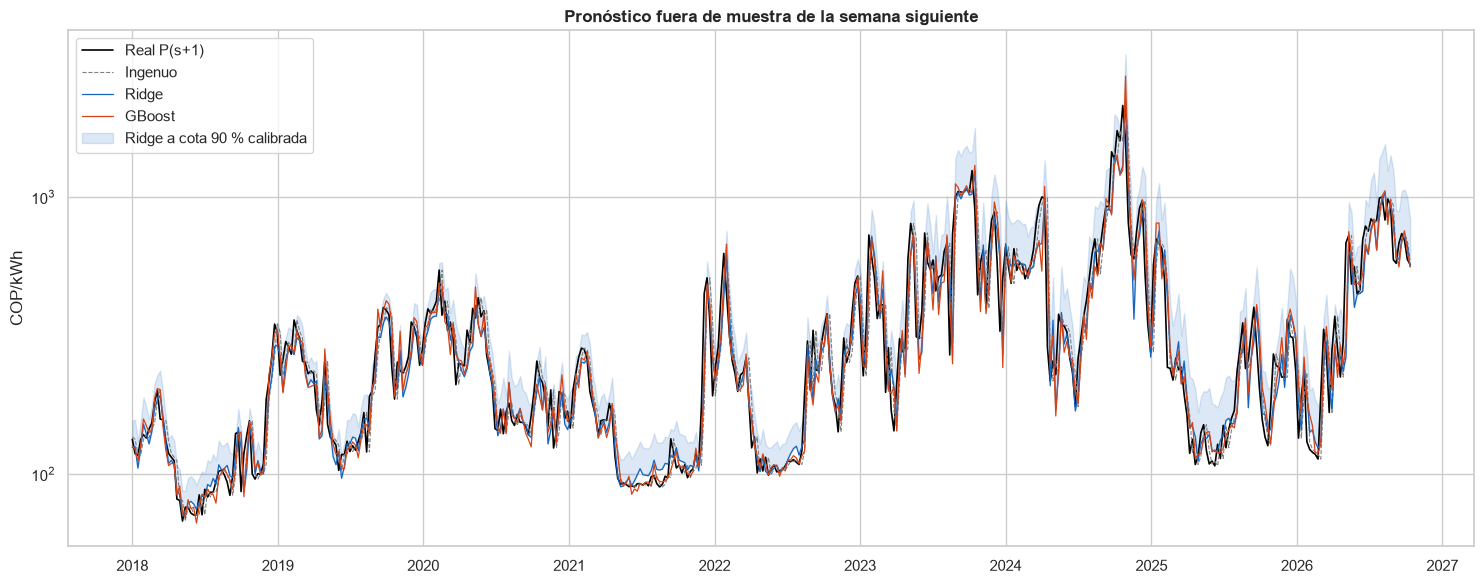

In [10]:
fig, ax = plt.subplots(figsize=(15, 6))
ax.plot(pred.index, pred.real, color="black", lw=1.2, label="Real P(s+1)")
ax.plot(pred.index, pred.Ingenuo, color="gray", lw=0.8, ls="--", label="Ingenuo")
ax.plot(pred.index, pred.Ridge, color="#1565c0", lw=0.9, label="Ridge")
ax.plot(pred.index, pred.GBoost, color="#d84315", lw=0.9, label="GBoost")
ax.fill_between(pred.index, pred.Ridge, pred.Ridge_cota90, color="#1565c0", alpha=0.15, label="Ridge a cota 90 % calibrada")
ax.set_yscale("log"); ax.legend(); ax.set_ylabel("COP/kWh")
ax.set_title("Pronóstico fuera de muestra de la semana siguiente")
plt.tight_layout()

## 6. Factores asociados al pronóstico

Coeficientes estandarizados de Ridge (signo y magnitud del efecto sobre el cambio log) e importancia por permutación del gradient boosting (aumento del MAE en el periodo de prueba al desordenar la variable).

,coef_ridge,perm_gboost
ultimo_dia_rel,0.109,0.049
log_precio,-0.040,0.005
embalse_cambio,-0.067,0.004
aportes_pct_media,0.008,0.004
momentum,-0.015,0.003
max_h_rel,0.001,0.002
sen_semana,-0.064,0.002
cv_diario,0.026,0.002
brecha_oferta_nt,0.032,0.001
aportes_pct_media_4s,0.049,0.001


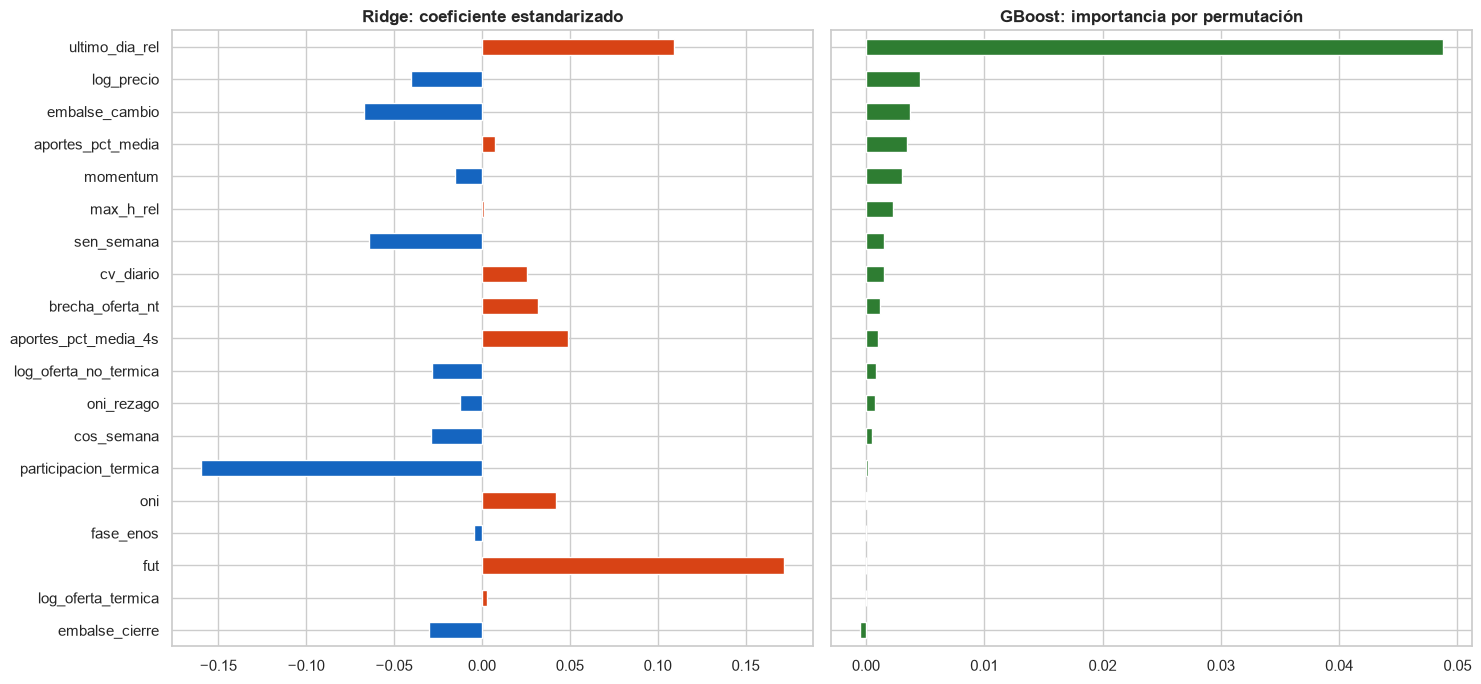

In [11]:
imp = mod.importancias(d, INICIO_PRUEBA)
fig, axes = plt.subplots(1, 2, figsize=(15, 7), sharey=True)
imp.coef_ridge.plot.barh(ax=axes[0], color=np.where(imp.coef_ridge > 0, "#d84315", "#1565c0"))
axes[0].set_title("Ridge: coeficiente estandarizado")
imp.perm_gboost.plot.barh(ax=axes[1], color="#2e7d32")
axes[1].set_title("GBoost: importancia por permutación")
axes[0].invert_yaxis()
plt.tight_layout()
imp.round(4)

### Aporte de cada grupo de variables

Ridge en el mismo walk-forward con solo las variables del precio, añadiendo un grupo del sistema a la vez y con todas. Responde directamente la pregunta de investigación: cuánto suman embalse, aportes, ofertas, utilización térmica y ENOS a lo que ya dice el propio precio.

,MAE,mejora_vs_ingenuo
ingenuo,66.553,0.000
solo precio,57.786,0.132
precio + hidrologia,56.877,0.145
precio + ofertas,57.106,0.142
precio + termica,57.101,0.142
precio + enos,57.904,0.130
precio + calendario,56.695,0.148
todas,54.303,0.184


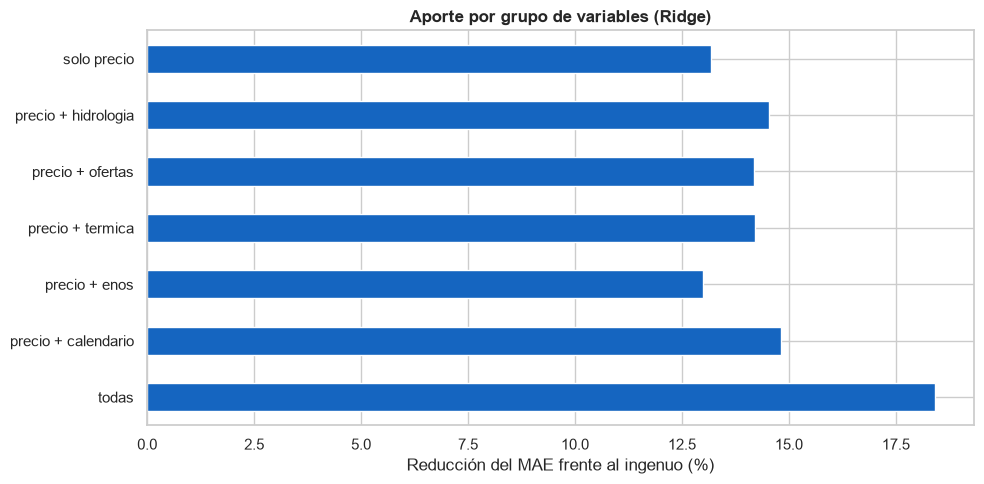

In [12]:
abl = mod.ablacion(d, INICIO_PRUEBA)
ax = abl.mejora_vs_ingenuo.drop("ingenuo").mul(100).plot.barh(figsize=(10, 5), color="#1565c0")
ax.set_xlabel("Reducción del MAE frente al ingenuo (%)"); ax.set_title("Aporte por grupo de variables (Ridge)")
ax.invert_yaxis(); plt.tight_layout()
abl

## 7. Cota superior al 90 % para la garantía

El cuantil 90 % del gradient boosting no es confiable como cota. Se comparan tres alternativas, todas evaluadas fuera de muestra desde 2018:

- **GBoost q90**: cuantil 90 % del modelo, sin calibrar.
- **Ridge cota 90 %**: pronóstico Ridge más un margen conformal, igual al cuantil 90 % de los errores log de las últimas 104 semanas ya observadas.
- **Ridge cota 90 % vol**: igual, pero el margen se escala con la volatilidad del precio en las últimas 4 semanas, de modo que la cota se ensancha cuando el mercado está agitado.

La ventana de 104 semanas se fijó antes de ver los resultados; la tabla de sensibilidad muestra que la conclusión no depende de esa elección. *Holgura* es cuánto excede la cota al precio real cuando lo cubre (recursos inmovilizados de más) y *faltante* cuánto se queda corta cuando no (exposición sin cubrir). La pérdida pinball resume ambos con el peso del nivel 90 %.

In [13]:
cotas = ["GBoost_q90", "Ridge_cota90", "Ridge_cota90_vol"]
mod.evaluar_cota(pred, cotas)

,cobertura,cobertura_min_anual,cobertura_normal,cobertura_alta_var,holgura_media_%,faltante_medio_%,pinball
GBoost_q90,0.834,0.731,0.896,0.587,30.771,11.192,16.132
Ridge_cota90,0.902,0.846,0.954,0.696,36.441,11.232,15.718
Ridge_cota90_vol,0.908,0.830,0.935,0.804,49.779,12.665,20.973


,GBoost_q90,Ridge_cota90,Ridge_cota90_vol
semana,,,
2018,0.870,0.890,0.940
2019,0.830,0.850,0.900
2020,0.830,0.920,0.880
2021,0.900,0.960,0.920
2022,0.830,0.880,0.940
2023,0.730,0.870,0.880
2024,0.810,0.910,0.830
2025,0.880,0.940,0.940
2026,0.830,0.900,0.930


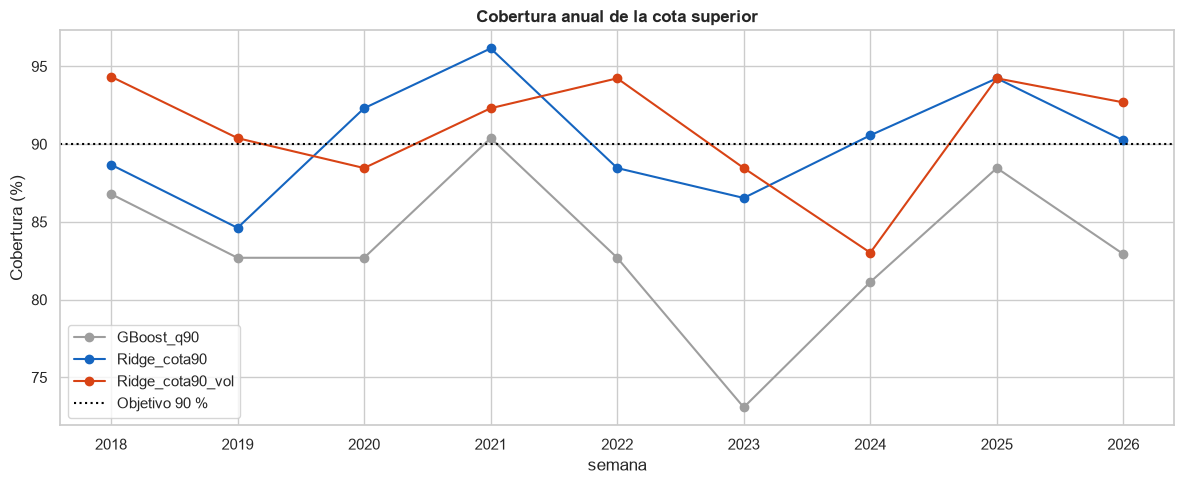

In [14]:
cob_anual = pd.DataFrame({c: (pred.real <= pred[c]).groupby(pred.index.year).mean() for c in cotas})
ax = cob_anual.mul(100).plot(marker="o", figsize=(12, 5), color=["#9e9e9e", "#1565c0", "#d84315"])
ax.axhline(90, color="black", ls=":", label="Objetivo 90 %")
ax.set_ylabel("Cobertura (%)"); ax.set_title("Cobertura anual de la cota superior"); ax.legend()
plt.tight_layout()
cob_anual.round(2)

In [15]:
# Sensibilidad a la ventana de calibración (None = toda la historia previa)
sens = {}
for v in (52, 104, 156, None):
    tmp = pred_todo.assign(cota=mod.conformal(pred_todo, "Ridge", ventana=v))
    sens[f"ventana {v or 'expansiva'}"] = mod.evaluar_cota(tmp[tmp.index >= INICIO_PRUEBA], ["cota"]).iloc[0]
pd.DataFrame(sens).T

,cobertura,cobertura_min_anual,cobertura_normal,cobertura_alta_var,holgura_media_%,faltante_medio_%,pinball
ventana 52,0.928,0.885,0.970,0.761,40.485,12.023,16.427
ventana 104,0.902,0.846,0.954,0.696,36.441,11.232,15.718
ventana 156,0.893,0.769,0.951,0.663,35.378,10.853,15.493
ventana expansiva,0.878,0.731,0.935,0.652,32.762,11.475,15.546


## 8. Pronóstico para la semana siguiente

In [16]:
prox = mod.pronostico_siguiente(d, pred_todo)
print(f"Semana base: {prox.semana_base:%Y-%m-%d} (precio {prox.precio_base:,.1f} COP/kWh)")
print(f"Semana pronosticada: {prox.semana_base + pd.Timedelta(weeks=1):%Y-%m-%d}")
prox.drop(["semana_base"]).astype(float).round(1).to_frame("COP/kWh")

Semana base: 2026-10-19 (precio 569.8 COP/kWh)
Semana pronosticada: 2026-10-26


,COP/kWh
precio_base,569.800
Ridge,498.400
GBoost,517.800
GBoost_q90,693.300
Ridge_cota90,741.200
Ridge_cota90_vol,585.500


## Conclusiones

Resultados con los datos descargados el 3 de noviembre de 2026 (877 semanas, 2010-01-04 a 2026-10-19; prueba fuera de muestra de 459 semanas desde 2018).

- **Capacidad predictiva.** Ridge reduce el MAE frente al precio de la semana anterior en 18.4 % (54.3 frente a 66.6 COP/kWh; MAPE 14.8 % frente a 19.3 %). El gradient boosting logra 14.8 %. Ambas mejoras son significativas (Diebold–Mariano, p < 0.01).
- **Dónde está la mejora.** En semanas normales los modelos no superan al ingenuo (MAE ≈ 40 COP/kWh en los tres). Toda la ganancia aparece en las semanas de alta variabilidad (quintil superior del cambio real): de 171 a 110 COP/kWh. Es justamente el caso relevante para la garantía.
- **Qué variables aportan.** El precio de la propia semana explica la mayor parte: con solo esas variables la mejora es de 13.2 %. Cada grupo del sistema por separado añade entre 0 y 1.6 puntos, y todos juntos llevan la mejora a 18.4 %. La variable individual más útil es el precio del último día frente al promedio semanal (la tendencia dentro de la semana). Le siguen el cambio semanal del embalse y los aportes respecto a la media.
- **ENOS.** A una semana de horizonte el ONI no mejora el pronóstico (13.0 % frente a 13.2 % sin él). Su efecto ya está contenido en el embalse, los aportes y el nivel del precio. La hipótesis de un aporte con rezago podría tener sentido en horizontes mensuales, no en el semanal.
- **Años difíciles.** 2023 y 2024 concentran los mayores errores (MAE de 110 a 150 COP/kWh), por El Niño 2023–24 y la sequía de 2024. Coincide con la pérdida de desempeño en régimen de estrés que reporta Herrera-Mejía et al. (2026).
- **Cota para la garantía.** El pronóstico central subestima el precio en 55 % de las semanas, y el cuantil 90 % del gradient boosting cubre solo 83 % (73 % en 2023). Con calibración conformal sobre Ridge la cobertura sube a 90.2 % (peor año 84.6 %), con la menor pérdida pinball (15.7) y una holgura media de 36 % sobre el precio real. El inconveniente es que la cobertura no es pareja: 95 % en semanas normales y 70 % en las de alta variabilidad.
- **Alternativa por volatilidad.** Escalar el margen con la volatilidad reciente eleva la cobertura en semanas agitadas a 80 % (91 % global), a cambio de más holgura (50 %) y mayor pérdida pinball (21.0). Cuál conviene depende del costo relativo de inmovilizar recursos frente a quedar descubierto, que debe definir XM con la regla de la garantía.

**Pendiente de validar con XM:** la definición de semana, el criterio de ponderación de las ofertas, la versión del precio disponible al emitir el pronóstico y los pronósticos que usan hoy los agentes como referencia adicional.